# 01 — Feasibility: can Sentinel-1 see rice fields?

**Question:** do rice parcels have a Sentinel-1 radar time series that clearly differs from other parcels?
If not, there is no point in training a model. This notebook looks at one 10 × 10 km square in the Camargue
(Rhône delta, France) for the **2024** season.

**Expected signal** (radar physics):
- **Flooding (Apr–May):** a flooded field is a mirror. The radar pulse reflects away from the satellite, so the
  backscatter is very **low**. Few other crops are flooded in spring, so this dip is the strongest cue.
- **Growth (Jun–Aug):** leaves and stems scatter the pulse back (volume scattering; plus "double bounce" stem ↔ water),
  so backscatter **rises**, most clearly in the cross-polarisation VH.
- **Drainage and harvest (Sep–Oct):** water is let out before the harvest; then stubble or bare soil remains.

**Why 2024 and not 2025?** The plan is to train on 2024 and do the final test on 2025. Everything we look at while
designing the method (this notebook included) influences our choices. Looking at the test year now would be
*test-set peeking*, a form of data leakage that makes the final score too optimistic. So 2025 stays untouched.

**Data**
- Sentinel-1 GRD (IW, VV + VH), descending orbits, from the Copernicus Data Space Ecosystem through eo-learn.
- Labels: French RPG 2024 (Registre Parcellaire Graphique), the parcels farmers declare for EU CAP subsidies, with their crop.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from eolearn.core import EOPatch

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
warnings.filterwarnings("ignore", module="sentinelhub")
warnings.filterwarnings("ignore", module="eolearn")
plt.rcParams["figure.dpi"] = 72  # keeps the saved notebook small

from ricesar.config import DATA_DIR, load_config
from ricesar.download import PARCEL_FEATURE, S1_FEATURE, feasibility_bbox, patch_name, season_interval
from ricesar.features import parcel_timeseries, to_db
from ricesar.labels import load_labels, project, summary

config = load_config(PROJECT_ROOT / "configs" / "camargue.toml")
YEAR = config["feasibility"]["year"]
bbox = feasibility_bbox(config)
print("Year:", YEAR, "| season:", season_interval(config, YEAR))
print("Square:", bbox.crs.epsg, tuple(bbox), "->", patch_name(bbox))

Year: 2024 | season: ('2024-03-01', '2024-11-30')
Square: 32631 (620000.0, 4820000.0, 630000.0, 4830000.0) -> utm31n_620000_4820000


## 1. Labels: which parcels are rice?

The labels are downloaded once for the whole study area by `scripts/download_labels.py`.
Each parcel has a crop code (`code_cultu`, rice = `RIZ`) and a crop group. We add an integer id `pid` used to
"burn" the parcels into the raster.

**ML note — label quality.** These labels are *declarations* by farmers, not field checks. Most are right, but some
will be wrong or outdated (**label noise**). A model can never be "more right" than its labels in the evaluation,
so later we will look at parcels where model and label disagree most.

In [2]:
labels = load_labels(config, YEAR)
print(f"{len(labels)} parcels in the whole study area, {labels['is_rice'].sum()} rice")
summary(labels).head(8)

22988 parcels in the whole study area, 1566 rice


,parcels,area_ha
group_name,,
summer pasture,1133,34290.17
permanent grassland,2265,16764.85
rice,1567,13375.80
other cereals,1765,10080.91
vineyards,2840,7787.09
fodder,1256,5692.42
vegetables/flowers,2310,5514.65
orchards,2669,5082.16


411 parcels in the 10 km square, 125 rice


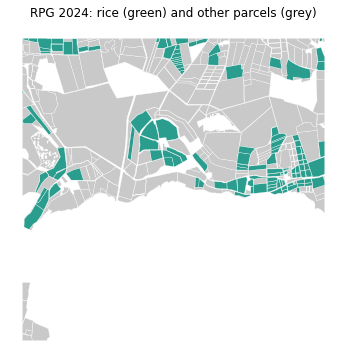

In [3]:
patch_parcels = project(labels, bbox.crs.pyproj_crs()).clip(bbox.geometry)
print(f"{len(patch_parcels)} parcels in the 10 km square, {patch_parcels['is_rice'].sum()} rice")

fig, ax = plt.subplots(figsize=(6, 6))
patch_parcels[~patch_parcels["is_rice"]].plot(ax=ax, color="#c9c9c9", edgecolor="white", linewidth=0.3)
patch_parcels[patch_parcels["is_rice"]].plot(ax=ax, color="#2a9d8f", edgecolor="white", linewidth=0.3)
ax.set_title(f"RPG {YEAR}: rice (green) and other parcels (grey)")
ax.set_axis_off()
plt.show()

## 2. Sentinel-1 download with eo-learn

`scripts/download_s1.py --year 2024 --area feasibility` runs this eo-learn workflow (code in `src/ricesar/download.py`):

1. `SentinelHubInputTask`: VV and VH backscatter for every pass in the season, as `sigma0` (linear power),
   orthorectified, at **20 m** (the true resolution of S1 GRD is about 20 m; the 10 m product is only finer pixel
   spacing, and 20 m costs 4× less of the free quota). Plus `dataMask` (1 = valid pixel).
2. `VectorToRasterTask`: burns each parcel's `pid` into a raster, after **shrinking each parcel by 20 m**, so that
   pixels mixing the parcel with a road or a neighbour are not used.
3. `SaveTask`: saves the EOPatch to `data/raw/`.

The next cell runs the download only if the EOPatch is missing (it needs CDSE credentials in `.env`).

In [4]:
eopatch_dir = DATA_DIR / "raw" / f"eopatches_{config['name']}_feasibility_{YEAR}" / patch_name(bbox)
if not eopatch_dir.exists():
    from ricesar.config import get_sh_config
    from ricesar.download import run_download

    run_download(config, get_sh_config(), labels, [bbox], YEAR, eopatch_dir.parent)

eopatch = EOPatch.load(str(eopatch_dir))
eopatch

EOPatch(
  bbox=BBox(((620000.0, 4820000.0), (630000.0, 4830000.0)), crs=CRS('32631'))
  timestamps=[2024-03-01 05:52:42, ...]<length=46>
  mask_timeless={
    PARCEL_ID: numpy.ndarray(shape=(500, 500, 1), dtype=int32)
  }
  mask={
    dataMask: numpy.ndarray(shape=(46, 500, 500, 1), dtype=bool)
  }
  data={
    S1: numpy.ndarray(shape=(46, 500, 500, 2), dtype=float32)
  }
)

Each date is one satellite pass. Two different descending **tracks** cover this square (about 05:44 and 05:52 UTC, labelled by their 5-minute slot).
They look at the ground from different angles (incidence angle), so their backscatter levels differ slightly.
We label each pass by its track.

In [5]:
times = pd.Series(pd.to_datetime(eopatch.timestamps))
tracks = times.dt.floor("5min").dt.strftime("%H:%M")
print(len(times), "passes;", tracks.value_counts().to_dict())

46 passes; {'05:50': 23, '05:40': 23}


## 3. What the radar sees

VH backscatter in dB on two dates of the same track: during flooding (May) and near the peak of growth (August).
Rice parcels are outlined.

**Speckle:** the grainy "salt and pepper" look is normal for radar (interference of many small scatterers inside
one pixel). It's noise, not information about single pixels. Averaging over all pixels of a parcel removes most of it,
which is one reason to work **per parcel** rather than per pixel.

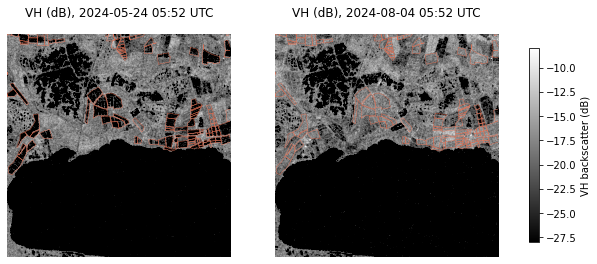

In [6]:
def closest_index(month_day, track):
    target = pd.Timestamp(f"{YEAR}-{month_day}")
    candidates = times[tracks == track]
    return int((candidates - target).abs().idxmin())

main_track = tracks.value_counts().index[0]
dates = [closest_index("05-20", main_track), closest_index("08-10", main_track)]
rice_outline = patch_parcels[patch_parcels["is_rice"]].boundary
extent = (bbox.min_x, bbox.max_x, bbox.min_y, bbox.max_y)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, t_idx in zip(axes, dates):
    vh_db = to_db(np.clip(eopatch[S1_FEATURE][t_idx, ..., 1], 1e-5, None))
    image = ax.imshow(vh_db, extent=extent, cmap="gray", vmin=-28, vmax=-8)
    rice_outline.plot(ax=ax, color="#e76f51", linewidth=0.4)
    ax.set_title(f"VH (dB), {times[t_idx]:%Y-%m-%d %H:%M} UTC")
    ax.set_axis_off()
fig.colorbar(image, ax=axes, shrink=0.7, label="VH backscatter (dB)")
plt.show()

## 4. Per-parcel time series: the rice curve

`parcel_timeseries` (in `src/ricesar/features.py`) averages all valid pixels of each parcel on each date.
The average is taken in **linear** units and converted to dB afterwards (averaging dB values would be biased low).
Parcels with fewer than 5 valid pixels are skipped.

Below: for each crop group, the median over parcels (line) and the middle 50 % of parcels (band), for the main
track only. dB is a log scale: +3 dB ≈ twice as much power returned.

In [7]:
series = parcel_timeseries([eopatch_dir])
series["track"] = pd.to_datetime(series["timestamp"]).dt.floor("5min").dt.strftime("%H:%M")
series = series.merge(labels[["pid", "is_rice", "group_name"]], on="pid")
print(series["pid"].nunique(), "parcels with data;", len(series), "parcel-date rows")
series.head()

355 parcels with data; 16329 parcel-date rows


,pid,pass,timestamp,n_pixels,VV,VV_db,VH,VH_db,VH_VV_db,track,is_rice,group_name
0,9054,2024-03-01 05:00:00,2024-03-01 05:52:42,6,0.092263,-10.349741,0.032742,-14.848940,-4.499199,05:50,False,other cereals
1,9054,2024-03-08 05:00:00,2024-03-08 05:44:32,6,0.033860,-14.703080,0.022220,-16.532580,-1.829500,05:40,False,other cereals
2,9054,2024-03-13 05:00:00,2024-03-13 05:52:42,6,0.058496,-12.328717,0.019894,-17.012692,-4.683975,05:50,False,other cereals
3,9054,2024-03-20 05:00:00,2024-03-20 05:44:33,6,0.060646,-12.172001,0.013277,-18.768878,-6.596877,05:40,False,other cereals
4,9054,2024-03-25 05:00:00,2024-03-25 05:52:43,6,0.024098,-16.180121,0.015227,-18.173731,-1.993610,05:50,False,other cereals


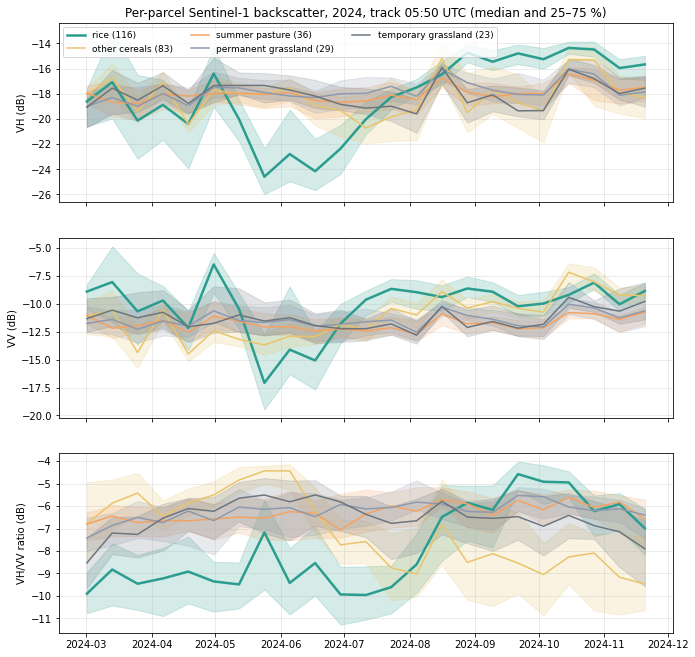

In [8]:
top_other = (
    series[~series["is_rice"]].drop_duplicates("pid")["group_name"].value_counts().head(4).index.tolist()
)
groups = ["rice"] + top_other
colors = dict(zip(groups, ["#2a9d8f", "#e9c46a", "#f4a261", "#8d99ae", "#6c757d"]))

one_track = series[series["track"] == main_track]
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
for ax, column, title in zip(
    axes, ["VH_db", "VV_db", "VH_VV_db"], ["VH (dB)", "VV (dB)", "VH/VV ratio (dB)"]
):
    for group in groups:
        stats = (
            one_track[one_track["group_name"] == group]
            .groupby("timestamp")[column]
            .quantile([0.25, 0.5, 0.75])
            .unstack()
        )
        n_parcels = one_track.loc[one_track["group_name"] == group, "pid"].nunique()
        ax.plot(stats.index, stats[0.5], color=colors[group], linewidth=2.5 if group == "rice" else 1.5,
                label=f"{group} ({n_parcels})")
        ax.fill_between(stats.index, stats[0.25], stats[0.75], color=colors[group], alpha=0.2)
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper left", ncol=3, fontsize=9)
axes[0].set_title(f"Per-parcel Sentinel-1 backscatter, {YEAR}, track {main_track} UTC (median and 25–75 %)")
fig.savefig(PROJECT_ROOT / "reports" / "figures" / "01_rice_vs_other_timeseries.png", dpi=90, bbox_inches="tight")
plt.show()

**How to read it:** look for the rice line (green) dropping well below the others in spring (flooding) and then
climbing above them in summer (growth). The width of the bands shows how similar parcels of one group are to each other.

Single parcels vary more than the median: some are flooded earlier or later, some are dry-seeded and flooded later.
Here are 15 random rice parcels:

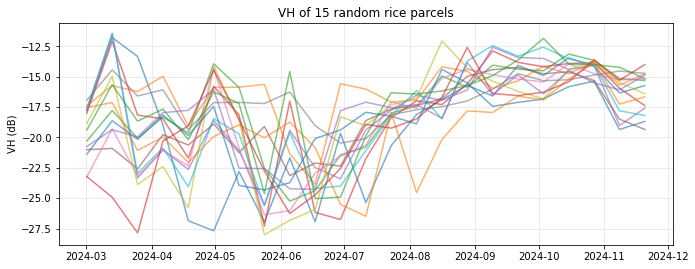

In [9]:
rng = np.random.default_rng(0)
sample_pids = rng.choice(one_track.loc[one_track["is_rice"], "pid"].unique(), size=15, replace=False)
fig, ax = plt.subplots(figsize=(11, 4))
for pid in sample_pids:
    parcel = one_track[one_track["pid"] == pid]
    ax.plot(parcel["timestamp"], parcel["VH_db"], alpha=0.6)
ax.set_ylabel("VH (dB)")
ax.set_title("VH of 15 random rice parcels")
ax.grid(alpha=0.3)
plt.show()

## 5. Do the two tracks agree?

If we later mix both tracks, a level difference between them would act like noise. Here is the rice median per track.

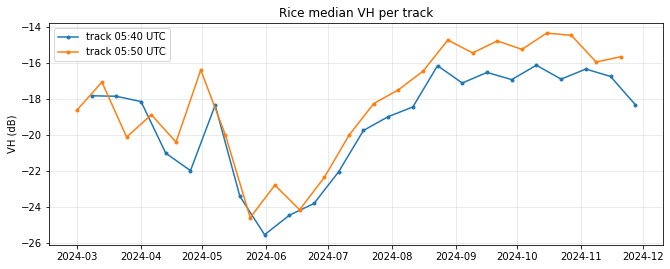

VH_db         VV_db       
is_rice  False  True   False  True 
track                              
05:40   -18.91 -18.48 -12.22 -10.99
05:50   -18.00 -17.53 -11.15  -9.67

In [10]:
fig, ax = plt.subplots(figsize=(11, 4))
for track, group in series[series["is_rice"]].groupby("track"):
    median = group.groupby("timestamp")["VH_db"].median()
    ax.plot(median.index, median.values, marker=".", label=f"track {track} UTC")
ax.set_ylabel("VH (dB)")
ax.set_title("Rice median VH per track")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

offsets = series.pivot_table(index="track", columns="is_rice", values=["VH_db", "VV_db"], aggfunc="median")
offsets.round(2)

## 6. A first look at separability

One number per parcel: the **lowest VH in the flooding window (Apr 15 – Jun 15)**, i.e. "how dark did it get".
If rice and the rest barely overlap on this single number, a model will have an easy job; where they overlap shows
which other parcels look like rice.

**ML note:** this is *exploratory* analysis on training data. The 2025 test season is not used, so the final test
stays honest.

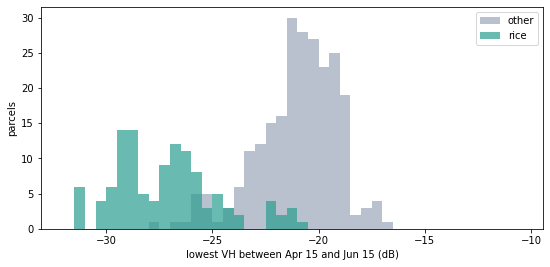

Other parcels darker than the rice median:


group_name
sunflower    1
Name: count, dtype: int64

In [11]:
window = series[
    (pd.to_datetime(series["timestamp"]) >= f"{YEAR}-04-15")
    & (pd.to_datetime(series["timestamp"]) <= f"{YEAR}-06-15")
]
flood_min = window.groupby("pid").agg(vh_min=("VH_db", "min"), is_rice=("is_rice", "first"),
                                      group_name=("group_name", "first"))

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(-32, -10, 0.5)
ax.hist(flood_min.loc[~flood_min["is_rice"], "vh_min"], bins=bins, alpha=0.6, label="other", color="#8d99ae")
ax.hist(flood_min.loc[flood_min["is_rice"], "vh_min"], bins=bins, alpha=0.7, label="rice", color="#2a9d8f")
ax.set_xlabel("lowest VH between Apr 15 and Jun 15 (dB)")
ax.set_ylabel("parcels")
ax.legend()
plt.show()

print("Other parcels darker than the rice median:")
rice_median = flood_min.loc[flood_min["is_rice"], "vh_min"].median()
flood_min[(~flood_min["is_rice"]) & (flood_min["vh_min"] < rice_median)]["group_name"].value_counts()

### A one-number rule, as a preview

A first "model": call a parcel rice if its lowest VH in the flooding window is below a threshold. The threshold is
read off the histogram above, i.e. chosen on this same data, so the scores below are **optimistic** (they measure how
well the rule fits the data it was tuned on, not how well it generalises). Proper evaluation comes in the next
notebooks: cross-validation on 2024, then the untouched 2025 season.

- **Precision** = of the parcels called rice, the share that really are rice (false alarms lower it).
- **Recall** = of the real rice parcels, the share that were found (misses lower it).

In [12]:
THRESHOLD_DB = -24
predicted = flood_min["vh_min"] < THRESHOLD_DB
actual = flood_min["is_rice"]
tp, fp = (predicted & actual).sum(), (predicted & ~actual).sum()
fn, tn = (~predicted & actual).sum(), (~predicted & ~actual).sum()
print(f"rice found: {tp}, missed: {fn} | false alarms: {fp}, correct 'other': {tn}")
print(f"precision {tp / (tp + fp):.2f}, recall {tp / (tp + fn):.2f}")

false_alarms = flood_min[predicted & ~actual].merge(labels[["pid", "code_cultu"]], left_index=True, right_on="pid")
print("False alarms by declared crop code:", false_alarms["code_cultu"].value_counts().to_dict())

rice found: 104, missed: 12 | false alarms: 17, correct 'other': 222
precision 0.86, recall 0.90
False alarms by declared crop code: {'MLO': 8, 'TOM': 4, 'TRN': 2, 'BTH': 2, 'MLT': 1}


## Conclusion

**Feasible: rice has a clear and distinctive Sentinel-1 signature in the Camargue.**

- In March–April rice parcels look like the others (VH about −18 dB). From early May they **drop to about −24 dB**
  (flooding) and stay low until about the end of June, then **rise to about −15 dB** from August to October, above every other
  crop group. VV shows the same dip, and the VH/VV ratio is lowest for rice in spring (on water, VH drops more than VV).
  This matches the expected physics, so the water is the rice's fingerprint, not a problem.
- **One number already separates most parcels:** the lowest VH in the flooding window (precision about 0.86, recall about 0.90 at
  −24 dB on this square; optimistic, see above).
- **What the one-number rule gets wrong**, which tells us what a model must learn:
  - *False alarms* are mostly **melon and tomato** fields (codes MLO, TOM): freshly planted vegetable beds (often with
    plastic mulch) are also smooth and dark in spring. They don't follow the summer rise of rice, so using the **whole
    season** (dip *and* rise) should remove most of them.
  - *Misses* are mostly **small rice parcels** (1–4 ha), where the 20 m edge buffer leaves few pixels, or parcels flooded
    later or less deeply (dry-seeded rice).
  - Natural marshes and the lagoon are also dark in May, but they **stay** dark in August, which rice doesn't.
- **The two tracks differ by about 1 dB** (different viewing angles; the 05:50 track is brighter for all parcels). Features must either use one track or be
  corrected per track.

**Next (notebook 02):** download the whole study area for 2024, build per-parcel features on a fixed time grid,
and compare a hand-made rule with machine-learning models using spatially blocked cross-validation.